# Naïve Bayes

Follows the *Naïve Bayes* slides. Run it cell by cell in class.

1. Probability basics
2. Bayes' theorem and the decision rule
3. Naïve Bayes on the 15-email table
4. Naïve Bayes on handwritten digits
5. The zero-probability problem and Laplace smoothing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

---
## 1. Probability basics

- **Random variable** $X$: gives a number to each outcome of an experiment. Example: $X$ = number of heads in 2 coin tosses, $X \in \{0, 1, 2\}$.
- **PMF** (discrete): $p(x) = P(X = x)$, with $\sum_x p(x) = 1$. Example: a fair die, $P(X = x) = \tfrac16$.
- **PDF** (continuous): $\int f(x)\,dx = 1$. The probability is the **area** $P(a \le X \le b) = \int_a^b f(x)\,dx$, not the height $f(x)$.
- **Joint** $P(X, Y)$: probability of each combination. **Marginal** $P(X) = \sum_y P(X, Y)$: row or column sums.
- **Expectation** $E[X] = \sum_x x\,p(x)$ (the average). **Variance** $\text{Var}[X] = E[X^2] - E[X]^2$ (the spread).

**The code below:** counts heads for the 4 coin outcomes, checks that the die's PMF sums to 1, shows that a PDF height can be above 1, computes the marginals of the attendance/pass table, and the die's mean and variance.

In [2]:
for o in ["HH", "HT", "TH", "TT"]:
    print(o, "-> X =", o.count("H"))

faces = np.arange(1, 7)
pmf = np.full(6, 1 / 6)
print("\nsum of the die's PMF:", round(pmf.sum(), 10))

print("narrow bell curve (σ=0.1) height at 0:", round(norm.pdf(0, 0, 0.1), 2), " <- bigger than 1!")
print("area P(-1 <= X <= 1) for σ=1        :", round(norm.cdf(1) - norm.cdf(-1), 3))

joint = pd.DataFrame([[0.42, 0.18],
                      [0.08, 0.32]],
                     index=["Present", "Absent"],
                     columns=["Pass", "Fail"])
print("\nmarginal of X (row sums)   :", joint.sum(axis=1).to_dict())
print("marginal of Y (column sums):", joint.sum(axis=0).to_dict())

E = np.sum(faces * pmf)
var = np.sum(faces**2 * pmf) - E**2
print(f"\ndie: E[X] = {E:.2f},  Var[X] = {var:.4f}")

HH -> X = 2
HT -> X = 1
TH -> X = 1
TT -> X = 0

sum of the die's PMF: 1.0
narrow bell curve (σ=0.1) height at 0: 3.99  <- bigger than 1!
area P(-1 <= X <= 1) for σ=1        : 0.683

marginal of X (row sums)   : {'Present': 0.6, 'Absent': 0.4}
marginal of Y (column sums): {'Pass': 0.5, 'Fail': 0.5}

die: E[X] = 3.50,  Var[X] = 2.9167


---
## 2. Conditional probability, Bayes' theorem, decision rule

$$p(X \mid Y) = \frac{p(X, Y)}{p(Y)} \qquad \text{independent: } p(X, Y) = p(X)\,p(Y)$$

$$\underbrace{p(\mathcal{C}_k \mid \mathbf{x})}_{\text{posterior}} = \frac{\overbrace{p(\mathbf{x} \mid \mathcal{C}_k)}^{\text{likelihood}}\ \overbrace{p(\mathcal{C}_k)}^{\text{prior}}}{p(\mathbf{x})}, \qquad p(\mathbf{x}) = \sum_k p(\mathbf{x} \mid \mathcal{C}_k)\,p(\mathcal{C}_k)$$

**Bayes decision rule:** choose the class with the larger posterior. Then $p(\text{error} \mid \mathbf{x})$ = the posterior of the class we did *not* choose.

**The code below** uses the same table, with the class = Pass/Fail and the feature $x$ = attendance:
- `joint.loc[x] / joint.loc[x].sum()` divides one row by its sum, which is Bayes' theorem (the row sum is the evidence $p(x)$)
- `idxmax()` picks the class with the bigger posterior (the decision rule)
- `1 - max` is the probability that the decision is wrong

In [3]:
P_X = joint.sum(axis=1)
P_Y = joint.sum(axis=0)

print("P(Present, Pass) =", joint.loc["Present", "Pass"],
      "  vs  P(Present)·P(Pass) =", round(P_X["Present"] * P_Y["Pass"], 2),
      "-> not independent")

for x in ["Present", "Absent"]:
    posterior = joint.loc[x] / joint.loc[x].sum()
    print(f"x = {x:8s} posterior = {posterior.round(2).to_dict()}"
          f" -> decide {posterior.idxmax()}, p(error|x) = {1 - posterior.max():.2f}")

P(Present, Pass) = 0.42   vs  P(Present)·P(Pass) = 0.3 -> not independent
x = Present  posterior = {'Pass': 0.7, 'Fail': 0.3} -> decide Pass, p(error|x) = 0.30
x = Absent   posterior = {'Pass': 0.2, 'Fail': 0.8} -> decide Fail, p(error|x) = 0.20


---
## 3. Naïve Bayes on the 15-email table

**Naïve Bayes** assumes the features are **conditionally independent given the class**:

$$p(x_1, \dots, x_d \mid \mathcal{C}_k) = \prod_{j=1}^{d} p(x_j \mid \mathcal{C}_k) \qquad\Longrightarrow\qquad \hat{\mathcal{C}} = \arg\max_k\ p(\mathcal{C}_k)\prod_j p(x_j \mid \mathcal{C}_k)$$

**The code below:**
- types in the table from the slides
- **prior:** `value_counts(normalize=True)` gives the fraction of each class
- **likelihood:** `pd.crosstab(..., normalize="index")` counts Yes/No **inside each class** and divides by the class size

In [4]:
emails = pd.DataFrame({
    "Free":  ["Yes","Yes","No","Yes","No","Yes","No","No","Yes","No","Yes","No","Yes","No","Yes"],
    "Prize": ["No","Yes","No","Yes","Yes","No","No","No","Yes","Yes","No","No","Yes","No","No"],
    "Class": ["Not Spam","Spam","Not Spam","Spam","Not Spam","Spam","Spam","Not Spam",
              "Spam","Spam","Not Spam","Not Spam","Spam","Not Spam","Not Spam"]},
    index=range(1, 16))

prior = emails["Class"].value_counts(normalize=True)
lik_free = pd.crosstab(emails["Class"], emails["Free"], normalize="index")
lik_prize = pd.crosstab(emails["Class"], emails["Prize"], normalize="index")

print("Prior:", prior.round(3).to_dict())
print("\nP(Free | Class):");  display(lik_free.round(3))
print("P(Prize | Class):");   display(lik_prize.round(3))

Prior: {'Not Spam': 0.533, 'Spam': 0.467}

P(Free | Class):


Free,No,Yes
Class,,
Not Spam,0.625,0.375
Spam,0.286,0.714


P(Prize | Class):


Prize,No,Yes
Class,,
Not Spam,0.875,0.125
Spam,0.286,0.714


**Prior:** 7 of 15 emails are spam, so $P(\text{Spam}) = \tfrac{7}{15}$ and $P(\text{Not Spam}) = \tfrac{8}{15}$.
**Likelihood:** for example, 5 of the 7 spam emails contain "Free", so $P(\text{Free}=\text{Yes} \mid \text{Spam}) = \tfrac57$.

### Slide question: classify an email that contains the word "Free"

**The code below:**
- `naive_bayes(**features)` multiplies **prior × one likelihood per given feature**, then divides by the total so the posteriors add up to 1. That's the naive assumption.
- First only "Free" is given, then both features.
- The last line counts the **exact** answer straight from the table, to compare with the naive one.

In [5]:
likelihoods = {"Free": lik_free, "Prize": lik_prize}

def naive_bayes(**features):
    score = {}
    for c in prior.index:
        score[c] = prior[c]
        for name, value in features.items():
            score[c] *= likelihoods[name].loc[c, value]
    total = sum(score.values())
    return {c: round(float(s / total), 3) for c, s in score.items()}

print("Free=Yes            ->", naive_bayes(Free="Yes"))
print("Free=Yes, Prize=Yes ->", naive_bayes(Free="Yes", Prize="Yes"))
print("Free=Yes, Prize=No  ->", naive_bayes(Free="Yes", Prize="No"))

rows = emails[(emails["Free"] == "Yes") & (emails["Prize"] == "No")]
print("\nexact P(Spam | Free=Yes, Prize=No) from the table:", round((rows["Class"] == "Spam").mean(), 3))

Free=Yes            -> {'Not Spam': 0.375, 'Spam': 0.625}
Free=Yes, Prize=Yes -> {'Not Spam': 0.095, 'Spam': 0.905}
Free=Yes, Prize=No  -> {'Not Spam': 0.648, 'Spam': 0.352}

exact P(Spam | Free=Yes, Prize=No) from the table: 0.25


- **Free only:** $\dfrac{\frac{7}{15}\cdot\frac57}{\frac{7}{15}\cdot\frac57 + \frac{8}{15}\cdot\frac38} = \dfrac{5}{8} = 0.625$, so we decide **Spam**.
- **Free + Prize:** 0.905 spam. Two spam clues make it very likely.
- **Free, no Prize:** only 0.352 spam, so the second feature **changes the decision** to Not Spam.
- The exact answer from the table is 0.25. Naive Bayes is an **approximation** because the features aren't truly independent, but it leads to the same decision, and it never needs to count every combination of features.

---
## 4. Naïve Bayes on handwritten digits

Every pixel $F_{i,j}$ of an 8 × 8 image is **on** or **off**, and the class $Y$ is the digit 0–9. The model learns $P(Y)$ and, for every pixel, $P(F_{i,j} = \text{on} \mid Y)$.

**The code below:**
- `X_gray > 7` turns each pixel on (1) or off (0)
- **`fit`**: prior = fraction of each digit. `P(on | Y)` = how often each pixel is on in that digit's images. `alpha` is the smoothing, used in Section 5.
- **`predict`**: score = $\log P(Y) + \sum_{\text{pixels}} \log P(\text{pixel value} \mid Y)$. `np.where` picks $P(\text{on})$ for on pixels and $1 - P(\text{on})$ for off pixels. We use **logs** because multiplying 64 small numbers can round to 0.

P(Y): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
test accuracy: 0.883


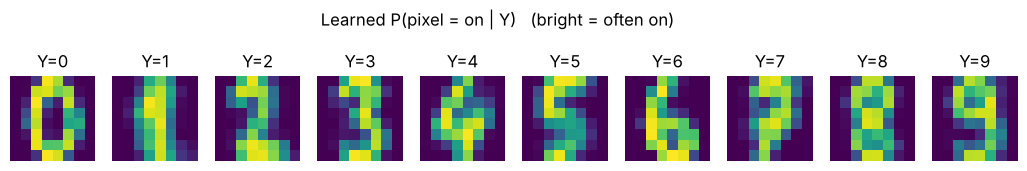

In [6]:
digits = load_digits()
X = (digits.data > 7).astype(int)
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

def fit(X, y, alpha=0):
    prior = np.array([np.mean(y == c) for c in range(10)])
    p_on = np.array([(X[y == c].sum(axis=0) + alpha) / ((y == c).sum() + 2 * alpha)
                     for c in range(10)])
    return prior, p_on

def predict(X, prior, p_on):
    with np.errstate(divide="ignore"):
        log_p = np.where(X[:, None, :] == 1, np.log(p_on), np.log(1 - p_on))
    scores = np.log(prior) + log_p.sum(axis=2)
    return scores.argmax(axis=1), scores

prior_d, p_on = fit(X_train, y_train)
pred, _ = predict(X_test, prior_d, p_on)
print("P(Y):", prior_d.round(2))
print("test accuracy:", round(np.mean(pred == y_test), 3))

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for c in range(10):
    axes[c].imshow(p_on[c].reshape(8, 8), vmin=0, vmax=1)
    axes[c].set_title(f"Y={c}"); axes[c].axis("off")
plt.suptitle("Learned P(pixel = on | Y)   (bright = often on)", y=1.1); plt.show()

The prior is about 0.1 for every digit, like the slide. The pictures are the **likelihood tables** for all 64 pixels, and they look like "average" digits. Counting pixels alone gets about **88%** right.

---
## 5. The problem, and Laplace smoothing

If a pixel was **never** on for some digit in training, then $P(\text{on} \mid Y) = 0$. A new image with that pixel on gets **probability 0** for that digit, however well the other pixels fit. The model **overfits** its small training set.

**Laplace smoothing:** *pretend you saw every outcome once more than you actually did.*

$$P(\text{on} \mid Y) = \frac{\text{count(on)} + 1}{N_Y + 2}$$

**The code below** trains on only **10 images per digit**, once with `alpha=0` and once with `alpha=1`:
- `np.isinf(scores)` finds classes with score $-\infty$, i.e. probability 0
- it then shows one real test image whose **true digit** was ruled out by a single pixel (red square)

alpha=0:  accuracy = 0.622,  test images where every digit is impossible = 182
alpha=1:  accuracy = 0.835,  test images where every digit is impossible = 0


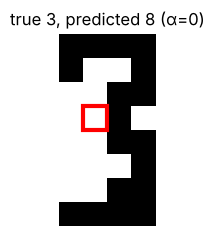

In [7]:
small = np.concatenate([np.where(y_train == c)[0][:10] for c in range(10)])
for alpha in [0, 1]:
    prior_s, p_on_s = fit(X_train[small], y_train[small], alpha)
    pred_s, scores = predict(X_test, prior_s, p_on_s)
    impossible = np.all(np.isinf(scores), axis=1).sum()
    print(f"alpha={alpha}:  accuracy = {np.mean(pred_s == y_test):.3f},  "
          f"test images where every digit is impossible = {impossible}")
    if alpha == 0:
        p_on_0, pred_0, scores_0 = p_on_s, pred_s, scores

true_score = scores_0[np.arange(len(y_test)), y_test]
i = np.where(np.isinf(true_score) & ~np.all(np.isinf(scores_0), axis=1))[0][0]
c = y_test[i]
bad = np.where((X_test[i] == 1) & (p_on_0[c] == 0) | (X_test[i] == 0) & (p_on_0[c] == 1))[0]

plt.figure(figsize=(2.5, 2.5))
plt.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
for p in bad:
    plt.gca().add_patch(plt.Rectangle((p % 8 - .5, p // 8 - .5), 1, 1, fill=False, ec="red", lw=3))
plt.title(f"true {c}, predicted {pred_0[i]} (α=0)"); plt.axis("off"); plt.show()

- With **α = 0**, many pixels have probability exactly 0 or 1, so for many test images **every** digit is impossible and accuracy drops to about 62%.
- In the picture, the image really is a 3. But the red pixel is **off**, while it was **on** in all 10 training 3s, so $P(Y = 3 \mid \text{image}) = 0$ and the model says 8.
- With **α = 1**, nothing is exactly 0 any more. On the **same data**, accuracy goes up to about 84%.

🗣️ **Ask the class:** what if α is huge, say 1000? *Every probability is pushed toward ½, the pixels stop mattering, and the model underfits.*

---
## Summary

| Idea | Key point |
|---|---|
| Bayes' theorem | posterior = likelihood × prior / evidence |
| Decision rule | choose the class with the largest posterior |
| Naïve Bayes | multiply one likelihood per feature (independent given the class) |
| Problem | one unseen value gives probability 0 and wipes out a class |
| Laplace smoothing | add 1 to every count: $\frac{\text{count}+1}{N+V}$ |